# Tổng hợp kết quả: phân loại nhóm liều warfarin bằng QML và ML cổ điển

Notebook này đọc các file kết quả đã lưu trong `results/`, vẽ lại bảng và biểu đồ chính, và lưu hình vào
`results/figures/` để dùng cho báo cáo và slide. Notebook không huấn luyện lại mô hình và không đụng tới
Final Test (chỉ đọc kết quả đã lưu), nên chạy hết trong vài giây.

Các mô hình:
- **Cổ điển:** LR (hồi quy logistic), SVM (máy vector hỗ trợ, kernel RBF), MLP (mạng nơ-ron nhỏ),
  HGB (cây tăng cường gradient), công thức IWPC (công thức dược di truyền đã công bố), Dummy (luôn đoán nhóm Vừa).
- **Lượng tử (mô phỏng):** QSVC (SVM dùng hàm nhân lượng tử với ZZ feature map, có rối lượng tử),
  QSVC-product (Z feature map, không rối lượng tử, dùng làm đối chứng), VQC (mạch lượng tử có tham số huấn luyện được).

Chỉ số chính là **Macro-F1**: trung bình F1 của 3 nhóm liều, nên nhóm ít bệnh nhân (nhóm Cao) có trọng số
ngang nhóm đông. **Recall nhóm Cao** là tỉ lệ bệnh nhân cần liều cao được mô hình nhận ra.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES = ROOT / "results"
FIG = RES / "figures"
FIG.mkdir(exist_ok=True)
pd.set_option("display.precision", 3)

QUANTUM = {"QSVC", "QSVC-product", "VQC"}
COLOR = {"LR": "#4C72B0", "SVM": "#55A868", "MLP": "#8C8C8C", "MLP-balanced": "#64B5CD", "HGB": "#8172B3",
         "QSVC": "#DD8452", "QSVC-product": "#C44E52", "VQC": "#937860", "IWPC": "#333333", "Dummy": "#BBBBBB"}

def save(fig, name):
    fig.savefig(FIG / name, dpi=200, bbox_inches="tight")

## 1. Dữ liệu

5.410 bệnh nhân đạt liều ổn định trong bộ IWPC. Nhóm liều: Thấp (≤ 21 mg/tuần), Vừa (21–49), Cao (≥ 49).
Tập Development có 4.328 người (dùng để huấn luyện và CV), Final Test có 1.082 người.

In [2]:
labels = pd.read_csv(ROOT / "data/interim/labels.csv", encoding="utf-8-sig")
split = pd.read_csv(ROOT / "data/splits/final_split.csv")
df = labels.merge(split, on="raw_row_index")
order = ["Low", "Intermediate", "High"]
tab = pd.crosstab(df.partition, df.target_group)[order]
tab.columns = ["Thấp", "Vừa", "Cao"]
tab["Tổng"] = tab.sum(axis=1)
tab

,Thấp,Vừa,Cao,Tổng
partition,,,,
development,1429,2349,550,4328
final_test,357,587,138,1082


## 2. Kết quả CV trên Development

CV 5-fold phân tầng theo trung tâm thu thập (Project Site), tinh chỉnh siêu tham số bằng inner 3-fold theo Macro-F1.
Mọi mô hình dùng cùng 4 đặc trưng (VKORC1, cân nặng, tuổi, CYP2C9), tương ứng 4 qubit.
`MLP` là bản không cân bằng lớp (phiên bản đầu), `MLP-balanced` là bản có cân bằng lớp như các mô hình khác.

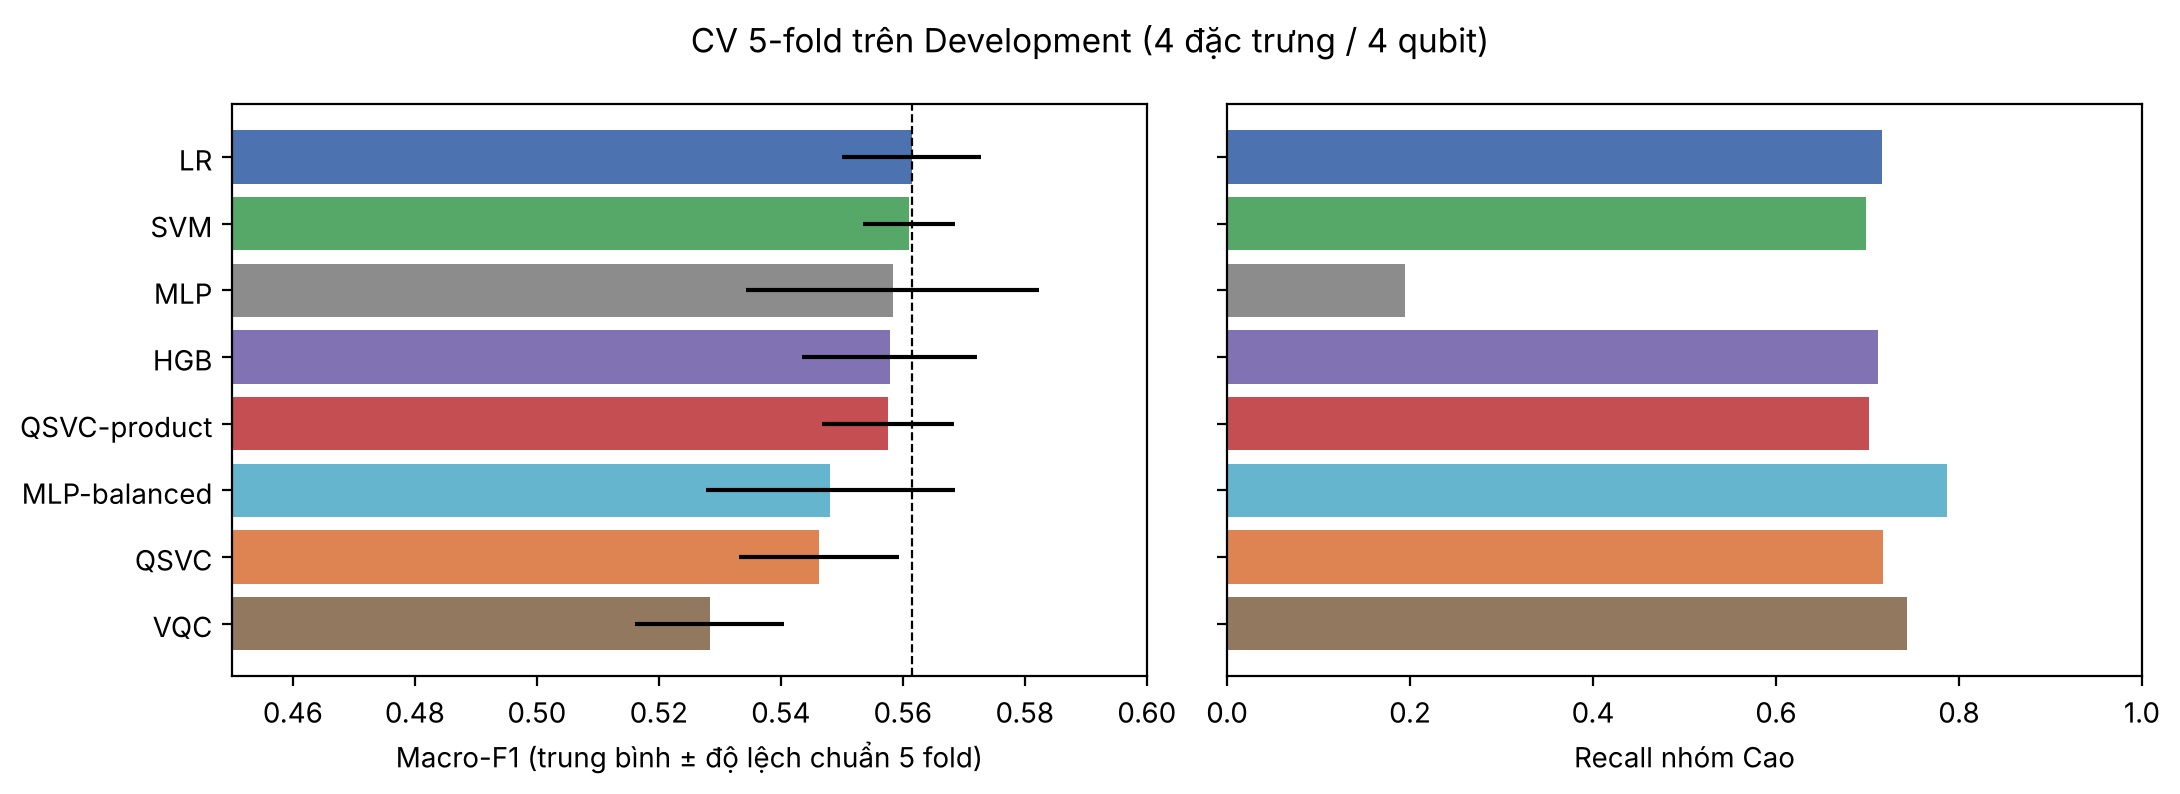

,model,macro_f1_mean,macro_f1_sd,recall_high_mean,recall_interm_mean
0,LR,0.561,0.011,0.716,0.431
1,SVM,0.561,0.007,0.699,0.464
2,MLP,0.558,0.024,0.195,0.815
3,HGB,0.558,0.014,0.712,0.447
4,QSVC-product,0.558,0.011,0.701,0.463
5,MLP-balanced,0.548,0.020,0.787,0.386
6,QSVC,0.546,0.013,0.717,0.441
7,VQC,0.528,0.012,0.744,0.382


In [3]:
cv = pd.read_csv(RES / "classification_cv/domain_k4_summary.csv")
cv = cv[cv.model != "Dummy"].sort_values("macro_f1_mean")
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
ax[0].barh(cv.model, cv.macro_f1_mean, xerr=cv.macro_f1_sd, color=[COLOR[m] for m in cv.model])
ax[0].set_xlim(0.45, 0.6); ax[0].set_xlabel("Macro-F1 (trung bình ± độ lệch chuẩn 5 fold)")
ax[0].axvline(cv.set_index("model").loc["LR", "macro_f1_mean"], ls="--", c="k", lw=0.8)
ax[1].barh(cv.model, cv.recall_high_mean, color=[COLOR[m] for m in cv.model])
ax[1].set_xlim(0, 1); ax[1].set_xlabel("Recall nhóm Cao")
fig.suptitle("CV 5-fold trên Development (4 đặc trưng / 4 qubit)")
fig.tight_layout(); save(fig, "cv_macro_f1.png"); plt.show()
cv.sort_values("macro_f1_mean", ascending=False).reset_index(drop=True)

## 3. CV lặp 5×5 và kiểm định thống kê

Lặp CV 5 lần với cách chia khác nhau (25 fold). Kiểm định t hiệu chỉnh Nadeau–Bengio phù hợp cho CV vì các fold
dùng chung dữ liệu huấn luyện. Vì so sánh 4 cặp cùng lúc, giá trị p được hiệu chỉnh thêm bằng phương pháp Holm.

In [4]:
rcv = pd.read_csv(RES / "repeated_cv/summary.csv")
display(rcv[["model", "macro_f1_mean", "macro_f1_sd", "accuracy_mean", "accuracy_sd", "recall_high_mean"]])
pd.read_csv(RES / "repeated_cv/nadeau_bengio.csv")

,model,macro_f1_mean,macro_f1_sd,accuracy_mean,accuracy_sd,recall_high_mean
0,SVM,0.564,0.013,0.579,0.013,0.703
1,LR,0.562,0.013,0.578,0.013,0.712
2,QSVC-product,0.561,0.014,0.577,0.013,0.708
3,QSVC,0.548,0.014,0.561,0.013,0.716
4,MLP-balanced,0.537,0.032,0.549,0.032,0.771
5,VQC,0.526,0.018,0.537,0.018,0.735


,pair,n_folds,mean_diff,t,p_value,significant_0.05,p_holm,significant_holm_0.05
0,QSVC - SVM,25,-1.570e-02,-2.332,2.840e-02,True,0.085,False
1,VQC - LR,25,-3.620e-02,-4.080,4.000e-04,True,0.002,True
2,QSVC - QSVC-product,25,-1.340e-02,-2.027,5.390e-02,False,0.108,False
3,LR - QSVC-product,25,9.000e-04,0.194,8.482e-01,False,0.848,False


Đọc bảng: chỉ cặp VQC – LR còn khác biệt có ý nghĩa sau hiệu chỉnh Holm. QSVC có xu hướng thấp hơn SVM và
QSVC-product, nhưng chưa đủ chắc chắn. LR và QSVC-product gần như bằng nhau.

## 4. Final Test

Tinh chỉnh trên Development, huấn luyện lại trên toàn bộ Development rồi dự đoán 1.082 bệnh nhân của Final Test.
Final Test đã được dùng nhiều lần để bổ sung mô hình (lịch sử trong `docs/final_configuration.md`), nên kết quả CV
ở mục 2–3 là bằng chứng chính, Final Test là kết quả tham khảo thêm.

In [5]:
ft = pd.concat([pd.read_csv(RES / "final_test/metrics.csv"), pd.read_csv(RES / "final_test/metrics_additional.csv")])
ft = ft.sort_values("macro_f1", ascending=False)
display(ft[["model", "macro_f1", "accuracy", "recall_low", "recall_intermediate", "recall_high", "qwk"]].reset_index(drop=True))
boot = json.loads((RES / "final_test/bootstrap_predeclared.json").read_text(encoding="utf-8"))
pd.DataFrame([{"cặp": k.replace("_vs_", " − "), "chênh lệch": v["mean_diff"], "KTC 95% dưới": v["ci_low"],
               "KTC 95% trên": v["ci_high"], "có ý nghĩa": v["significant"]}
              for g in ("predeclared", "existing_recomputed") for k, v in boot[g].items()])

,model,macro_f1,accuracy,recall_low,recall_intermediate,recall_high,qwk
0,LR,0.587,0.599,0.779,0.450,0.768,0.586
1,SVM,0.583,0.591,0.700,0.477,0.790,0.569
2,QSVC-product,0.582,0.591,0.697,0.480,0.783,0.572
3,HGB,0.577,0.585,0.723,0.455,0.783,0.573
4,MLP,0.575,0.665,0.588,0.806,0.261,0.517
5,MLP-balanced,0.575,0.584,0.751,0.433,0.797,0.573
6,QSVC,0.568,0.575,0.703,0.443,0.804,0.570
7,VQC,0.548,0.556,0.717,0.407,0.775,0.536
8,IWPC,0.541,0.644,0.412,0.876,0.261,0.442


,cặp,chênh lệch,KTC 95% dưới,KTC 95% trên,có ý nghĩa
0,QSVC − SVM,-0.015,-0.029,-0.001,True
1,VQC − LR,-0.039,-0.060,-0.017,True
2,QSVC − QSVC-product,-0.014,-0.024,-0.003,True
3,LR − QSVC-product,0.006,-0.012,0.022,False
4,QSVC-product − QSVC,0.014,0.003,0.024,True
5,QSVC-product − SVM,-0.001,-0.014,0.010,False


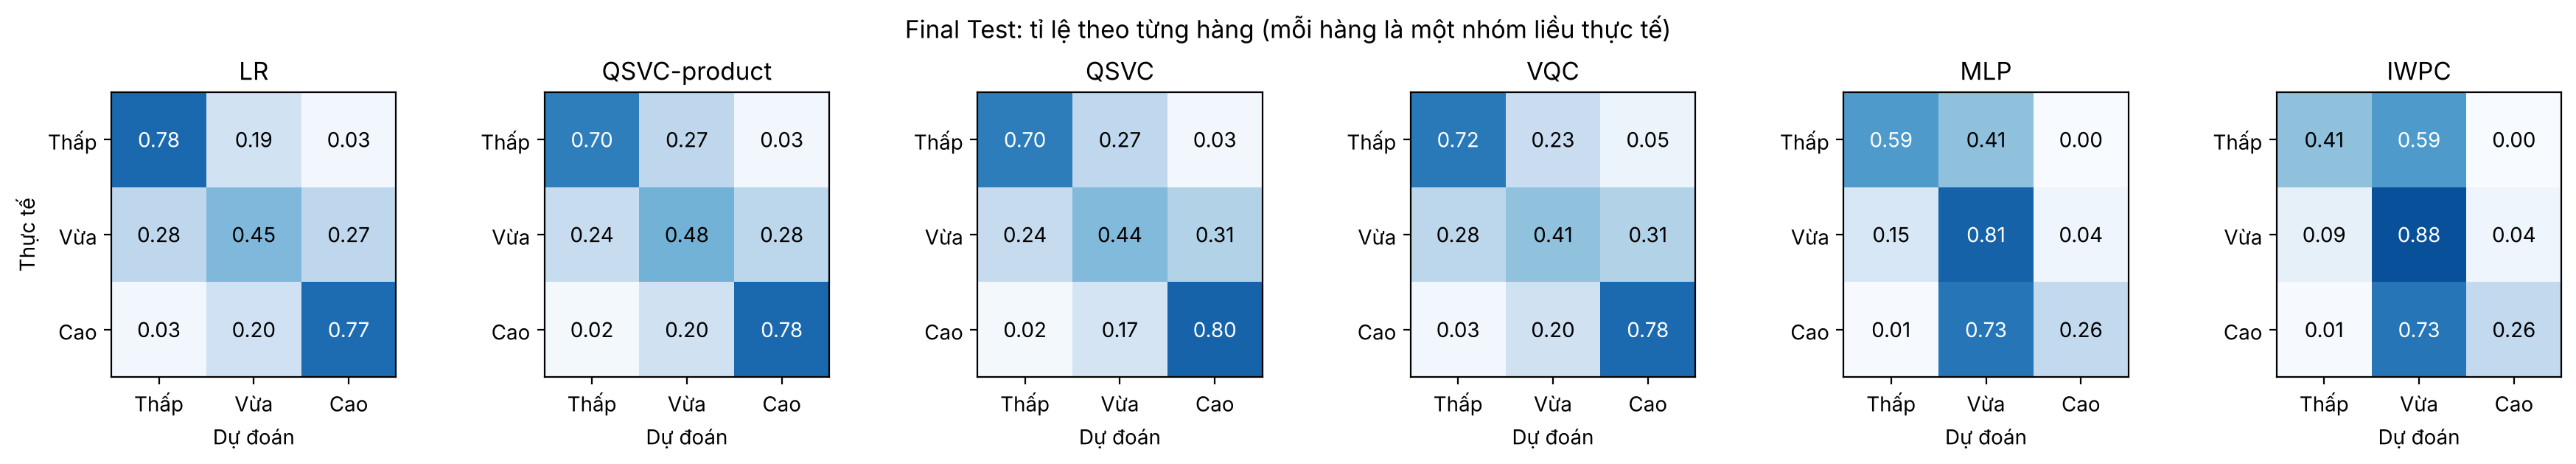

In [6]:
cm = pd.read_csv(RES / "final_test/confusion_matrices.csv")
models = ["LR", "QSVC-product", "QSVC", "VQC", "MLP", "IWPC"]
fig, axes = plt.subplots(1, len(models), figsize=(3 * len(models), 3))
names = ["Thấp", "Vừa", "Cao"]
for ax, m in zip(axes, models):
    M = cm[cm.model == m][["pred_Low", "pred_Intermediate", "pred_High"]].to_numpy()
    R = M / M.sum(axis=1, keepdims=True)
    ax.imshow(R, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{R[i, j]:.2f}", ha="center", va="center", color="white" if R[i, j] > 0.5 else "black")
    ax.set_xticks(range(3), names); ax.set_yticks(range(3), names); ax.set_title(m)
    ax.set_xlabel("Dự đoán")
axes[0].set_ylabel("Thực tế")
fig.suptitle("Final Test: tỉ lệ theo từng hàng (mỗi hàng là một nhóm liều thực tế)")
fig.tight_layout(); save(fig, "final_test_confusion.png"); plt.show()

MLP không cân bằng lớp và công thức IWPC dự đoán phần lớn là nhóm Vừa, nên bỏ sót khoảng 3/4 bệnh nhân nhóm Cao.
Các mô hình có cân bằng lớp nhận ra nhóm Cao tốt hơn nhiều, đổi lại nhầm một phần nhóm Vừa thành Thấp hoặc Cao.

## 5. Learning curve: ảnh hưởng của số mẫu huấn luyện

Trong mỗi fold của CV, lấy ngẫu nhiên n bệnh nhân từ phần huấn luyện, tinh chỉnh và đánh giá trên fold kiểm định.

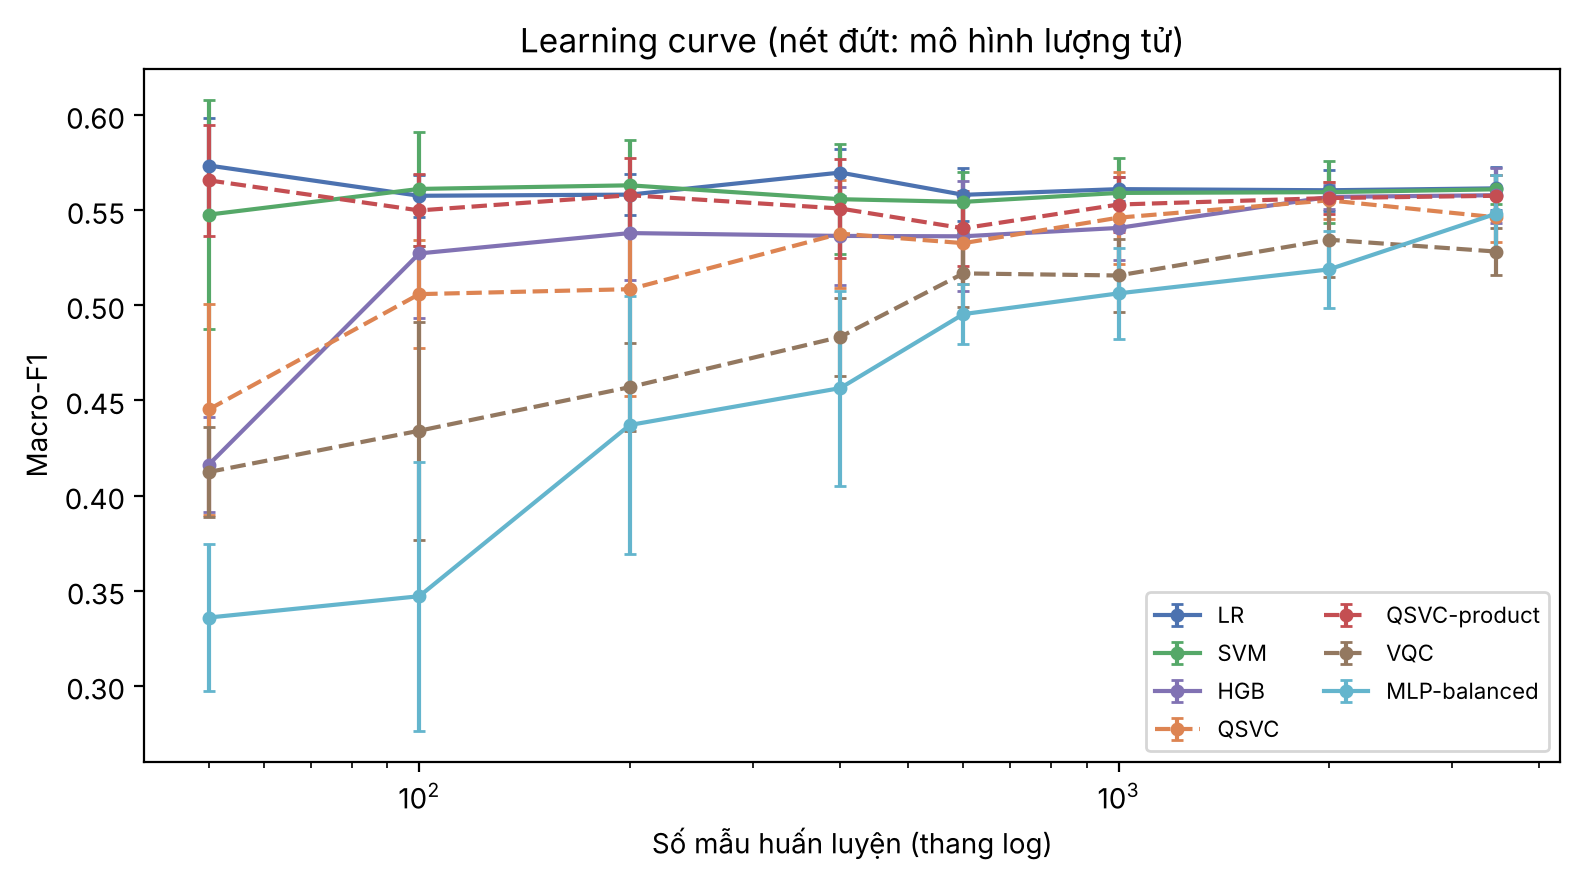

model,HGB,LR,MLP-balanced,QSVC,QSVC-product,SVM,VQC
train_n,,,,,,,
50.0,0.416,0.574,0.336,0.445,0.566,0.548,0.412
100.0,0.527,0.558,0.347,0.506,0.550,0.561,0.434
200.0,0.538,0.558,0.437,0.508,0.558,0.563,0.457
400.0,0.536,0.570,0.456,0.538,0.551,0.556,0.483
600.0,0.536,0.558,0.495,0.533,0.540,0.554,0.517
1000.0,0.541,0.561,0.506,0.546,0.553,0.559,0.516
2000.0,0.557,0.560,0.519,0.555,0.556,0.560,0.534
3462.4,0.558,0.562,0.548,0.546,0.558,0.561,0.528


In [7]:
lc = pd.read_csv(RES / "learning_curve_full/summary.csv")
fig, ax = plt.subplots(figsize=(8, 4.5))
for m, g in lc.groupby("model", sort=False):
    ax.errorbar(g.train_n, g.macro_f1_mean, yerr=g.macro_f1_sd, marker="o", ms=4, capsize=2,
                label=m, color=COLOR[m], ls="--" if m in QUANTUM else "-")
ax.set_xscale("log"); ax.set_xlabel("Số mẫu huấn luyện (thang log)"); ax.set_ylabel("Macro-F1")
ax.set_title("Learning curve (nét đứt: mô hình lượng tử)"); ax.legend(ncol=2, fontsize=8)
fig.tight_layout(); save(fig, "learning_curve.png"); plt.show()
lc.pivot(index="train_n", columns="model", values="macro_f1_mean").round(3)

LR, SVM và QSVC-product gần như ổn định từ khoảng 100 mẫu. QSVC, VQC, HGB và MLP-balanced cần nhiều dữ liệu
hơn. Khi dữ liệu ít, mô hình lượng tử không vượt được mô hình cổ điển.

## 6. Số đặc trưng / số qubit

k = 2, 4, 6 đặc trưng theo thứ tự VKORC1, cân nặng, tuổi, CYP2C9, chiều cao, giới tính. Với mô hình lượng tử,
mỗi đặc trưng là một qubit.

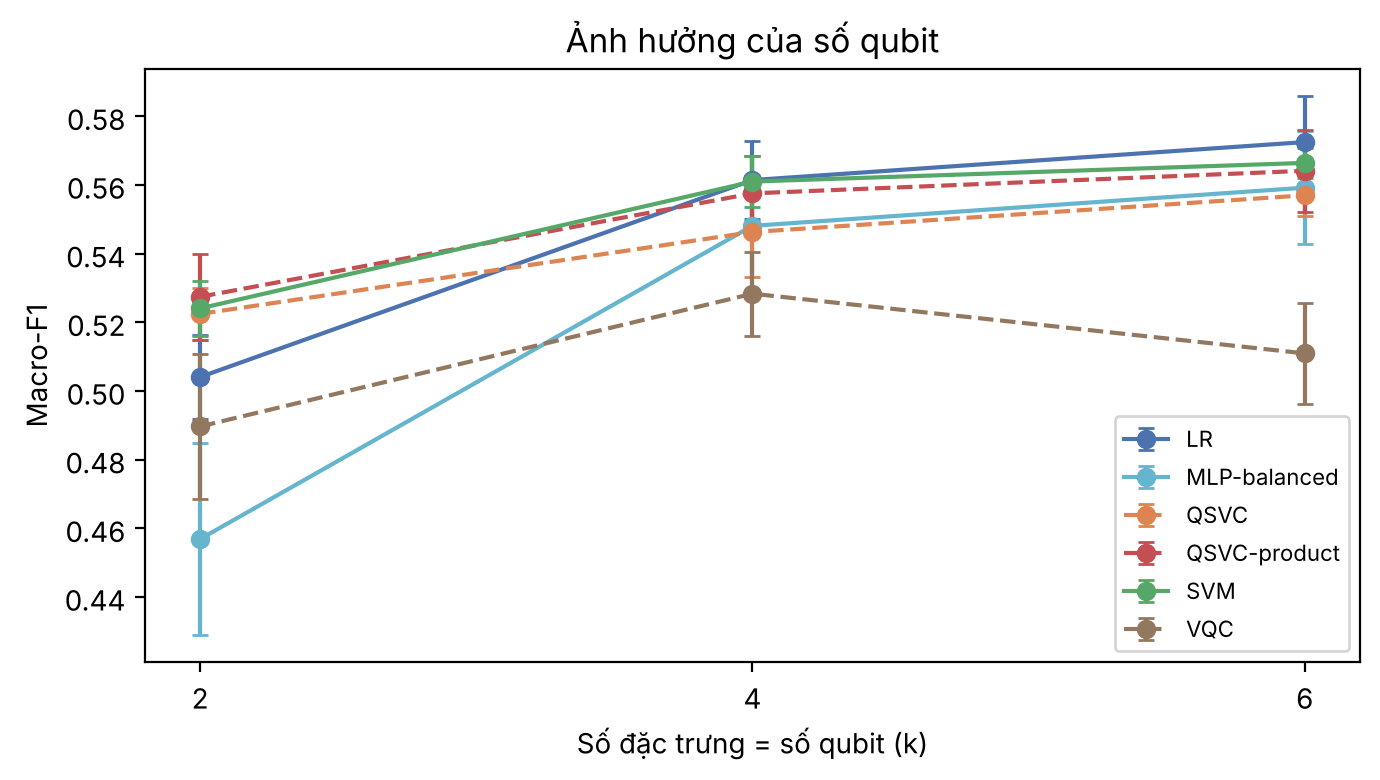

k,2,4,6
model,,,
LR,0.504,0.561,0.573
MLP-balanced,0.457,0.548,0.559
QSVC,0.522,0.546,0.557
QSVC-product,0.527,0.558,0.564
SVM,0.524,0.561,0.566
VQC,0.490,0.528,0.511


In [8]:
qb = pd.read_csv(RES / "ablation/qubit_summary.csv")
fig, ax = plt.subplots(figsize=(7, 4))
for m, g in qb.groupby("model"):
    g = g.sort_values("k")
    ax.errorbar(g.k, g.macro_f1_mean, yerr=g.macro_f1_sd, marker="o", capsize=3, label=m, color=COLOR[m],
                ls="--" if m in QUANTUM else "-")
ax.set_xticks([2, 4, 6]); ax.set_xlabel("Số đặc trưng = số qubit (k)"); ax.set_ylabel("Macro-F1")
ax.set_title("Ảnh hưởng của số qubit"); ax.legend(fontsize=8)
fig.tight_layout(); save(fig, "qubits_macro_f1.png"); plt.show()
qb.pivot(index="model", columns="k", values="macro_f1_mean").round(3)

Mô hình cổ điển và QSVC tốt lên khi có thêm đặc trưng, trong khi VQC giảm ở k = 6. Giới hạn số qubit
làm mất thông tin: chính số đặc trưng, chứ không phải việc chọn mô hình lượng tử hay cổ điển, là nút thắt lớn.

## 7. Chi phí tính toán

Đo trên fold 0 của CV (3.462 mẫu huấn luyện), 1 luồng CPU, mô phỏng statevector. Thời gian VQC ở k = 6 là ước tính.

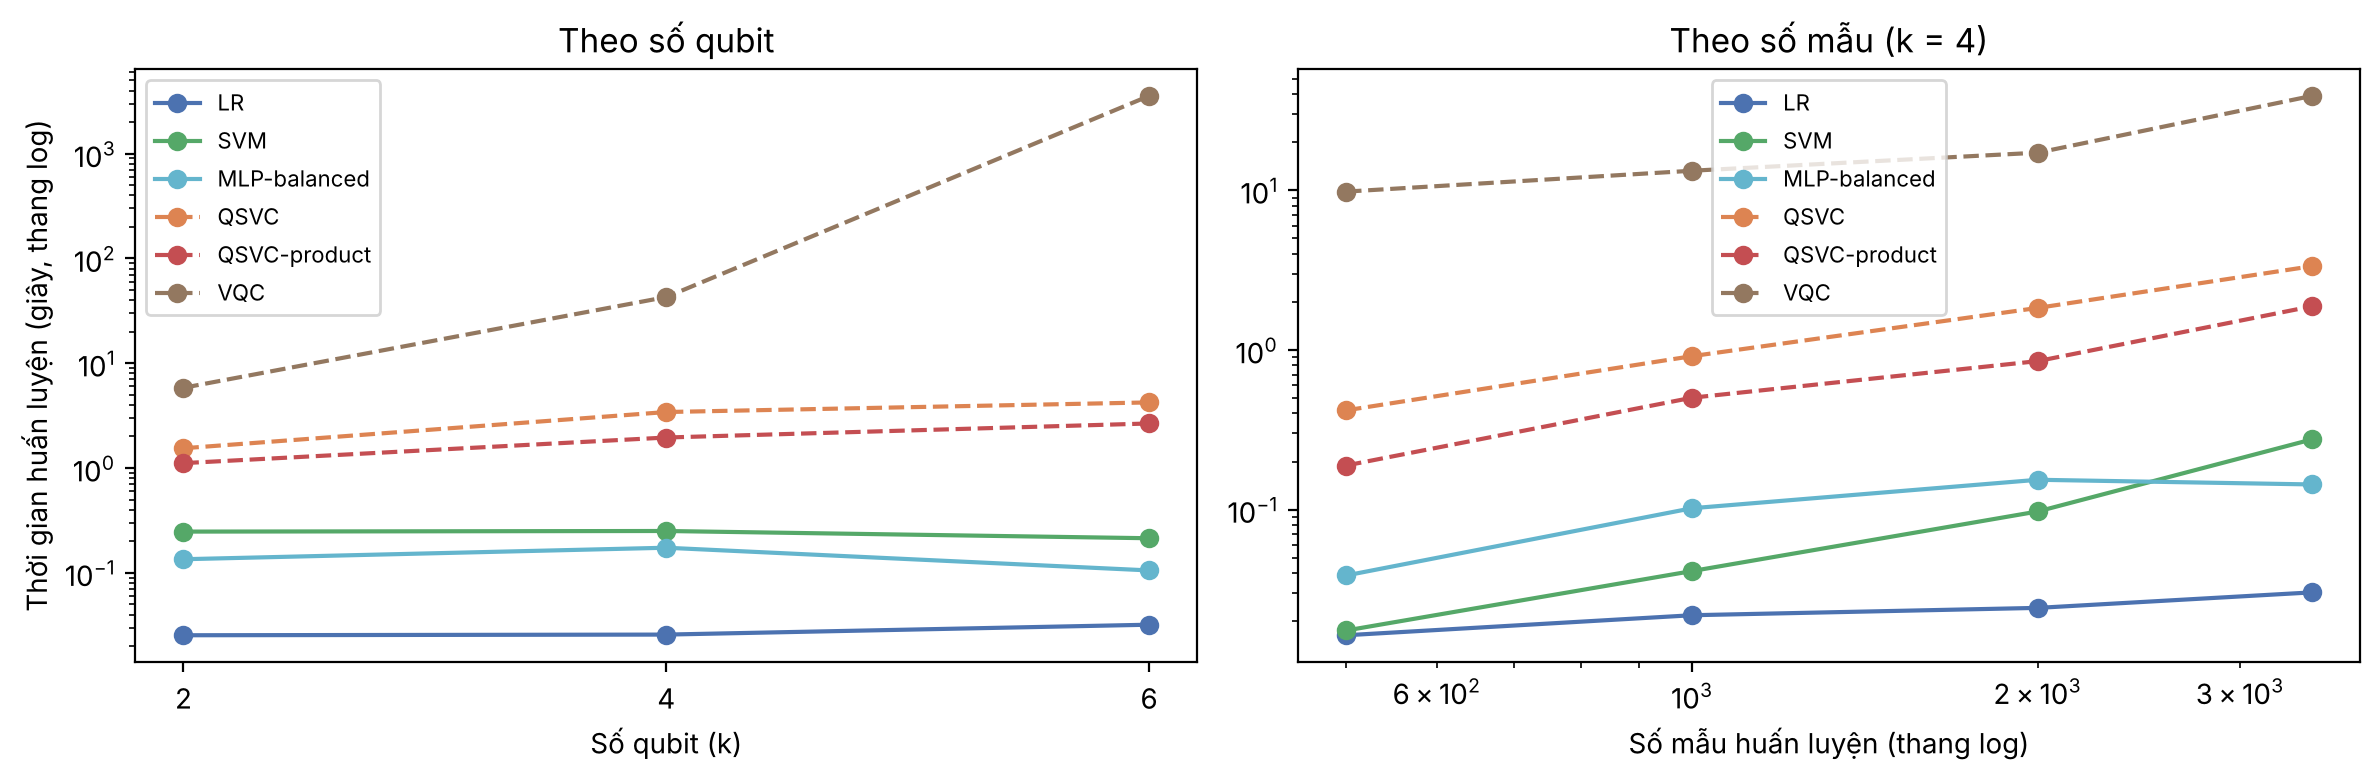

,model,k,fit_seconds,estimated,circuit_depth,cnot,quantum_params
0,LR,2,0.025,False,NaN,NaN,NaN
1,SVM,2,0.247,False,NaN,NaN,NaN
2,MLP-balanced,2,0.135,False,NaN,NaN,NaN
3,QSVC,2,1.544,False,10.0,4.0,0.0
4,QSVC-product,2,1.113,False,4.0,0.0,0.0
5,VQC,2,5.834,False,24.0,10.0,16.0
6,LR,4,0.026,False,NaN,NaN,NaN
7,SVM,4,0.251,False,NaN,NaN,NaN
8,MLP-balanced,4,0.174,False,NaN,NaN,NaN
9,QSVC,4,3.424,False,19.0,12.0,0.0


In [9]:
cq = pd.read_csv(RES / "cost/cost_by_qubits.csv")
cn = pd.read_csv(RES / "cost/cost_by_train_size.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for m, g in cq.groupby("model", sort=False):
    ax[0].plot(g.k, g.fit_seconds, marker="o", label=m, color=COLOR[m], ls="--" if m in QUANTUM else "-")
ax[0].set_yscale("log"); ax[0].set_xticks([2, 4, 6]); ax[0].set_xlabel("Số qubit (k)")
ax[0].set_ylabel("Thời gian huấn luyện (giây, thang log)"); ax[0].set_title("Theo số qubit"); ax[0].legend(fontsize=8)
for m, g in cn.groupby("model", sort=False):
    ax[1].plot(g.n_train, g.fit_seconds, marker="o", label=m, color=COLOR[m], ls="--" if m in QUANTUM else "-")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("Số mẫu huấn luyện (thang log)")
ax[1].set_title("Theo số mẫu (k = 4)"); ax[1].legend(fontsize=8)
fig.tight_layout(); save(fig, "cost.png"); plt.show()
cq[["model", "k", "fit_seconds", "estimated", "circuit_depth", "cnot", "quantum_params"]]

## 8. Shots và nhiễu: điều gì xảy ra trên máy lượng tử thật

Các kết quả trên dùng statevector chính xác. Trên máy thật, mỗi xác suất phải ước lượng bằng N lần đo (shots),
và mỗi cổng có thể bị lỗi. Thí nghiệm mô phỏng cả hai (CV 5-fold trên Development, tham số cố định).
Mức nhiễu thấp: lỗi 0,3% sau mỗi CNOT, 0,03% sau mỗi cổng 1 qubit, đọc nhầm 1%; mức cao: 1%, 0,1%, 3%.

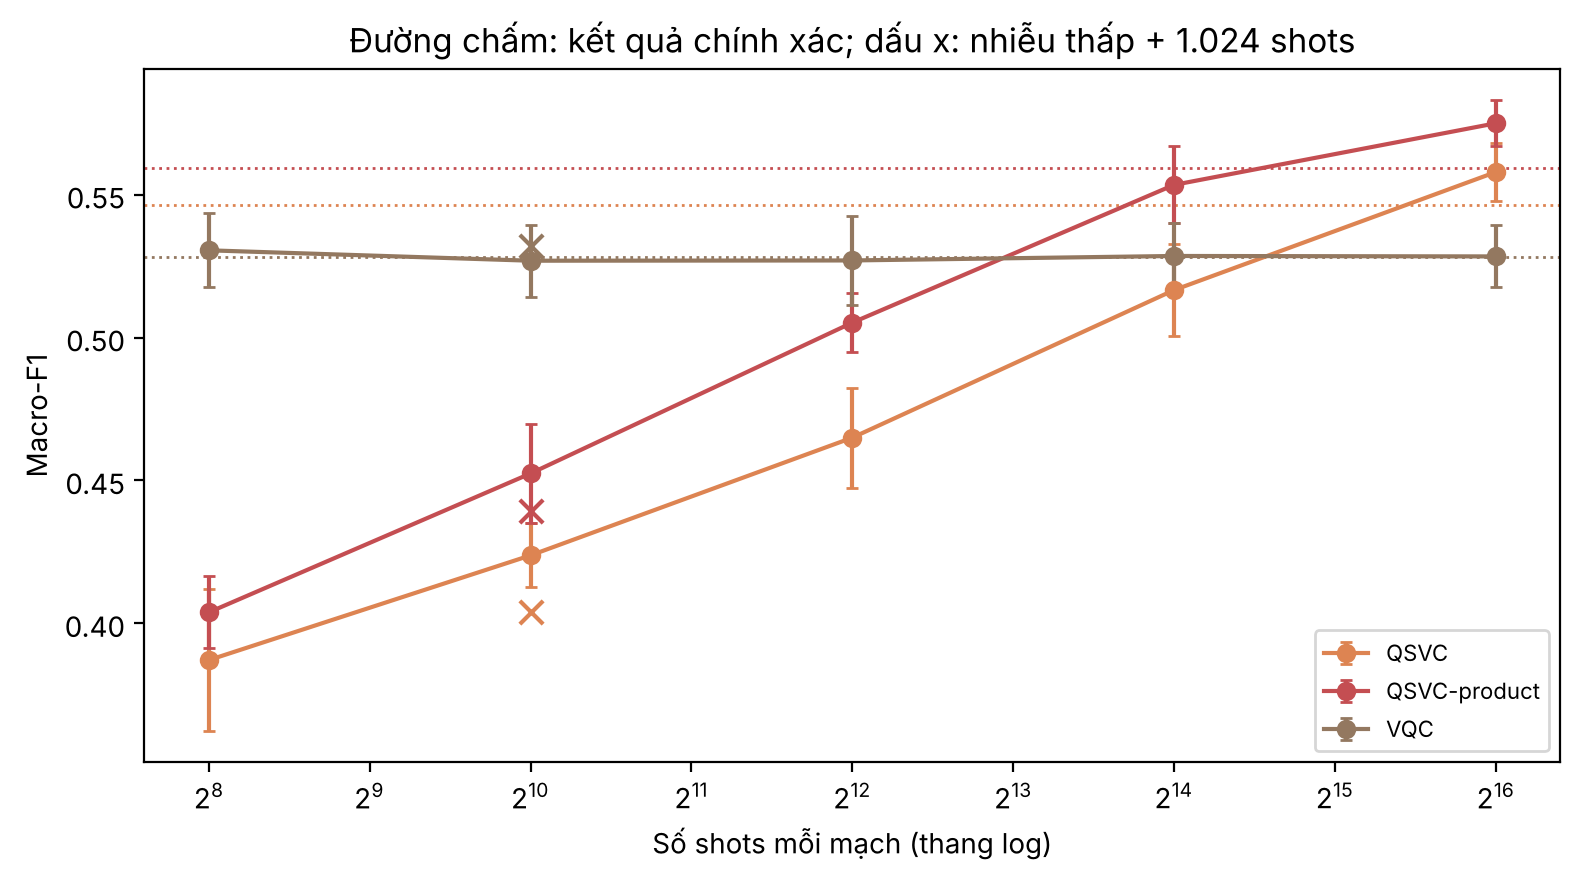

model         QSVC  QSVC-product    VQC
noise shots                            
none  0      0.546         0.559  0.528
      256    0.387         0.404  0.531
      1024   0.424         0.452  0.527
      4096   0.465         0.505  0.527
      16384  0.517         0.553  0.529
      65536  0.558         0.575  0.528
low   0      0.598         0.592  0.534
      1024   0.404         0.439  0.532
high  0      0.547         0.591  0.542
      1024   0.412         0.413  0.547

In [10]:
ns = pd.read_csv(RES / "noise/noise_summary.csv")
fig, ax = plt.subplots(figsize=(8, 4.5))
for m, g in ns.groupby("model", sort=False):
    s = g[(g.noise == "none") & (g.shots > 0)]
    exact = g[(g.noise == "none") & (g.shots == 0)].macro_f1_mean.iloc[0]
    ax.errorbar(s.shots, s.macro_f1_mean, yerr=s.macro_f1_std, marker="o", capsize=2, color=COLOR[m], label=m)
    ax.axhline(exact, color=COLOR[m], ls=":", lw=1)
    low = g[(g.noise == "low") & (g.shots == 1024)].macro_f1_mean.iloc[0]
    ax.scatter([1024], [low], marker="x", s=70, color=COLOR[m])
ax.set_xscale("log", base=2); ax.set_xlabel("Số shots mỗi mạch (thang log)"); ax.set_ylabel("Macro-F1")
ax.set_title("Đường chấm: kết quả chính xác; dấu x: nhiễu thấp + 1.024 shots")
ax.legend(fontsize=8); fig.tight_layout(); save(fig, "shots_noise.png"); plt.show()
ns.pivot_table(index=["noise", "shots"], columns="model", values="macro_f1_mean", sort=False).round(3)

In [11]:
display(pd.read_csv(RES / "noise/circuits.csv"))
pd.read_csv(RES / "noise/hardware_cost.csv")[["model", "total_circuits", "shots_per_circuit", "total_shots", "cx_per_circuit"]]

,model,circuit,qubits,depth,cx,one_qubit_noisy,rz,cx_transpiled_jointly,clean_run_prob_cx_0.3pct
0,QSVC,U(x_i) rồi U(x_j)†,4,46,24,16,60,22.0,0.930
1,QSVC-product,U(x_i) rồi U(x_j)†,4,16,0,16,48,0.0,1.000
2,VQC,2 lớp: ZZ feature map + RealAmplitudes (reps 3),4,65,30,68,82,NaN,0.914


,model,total_circuits,shots_per_circuit,total_shots,cx_per_circuit
0,QSVC,14046524,1000,14046524000,24
1,QSVC-product,14046524,1000,14046524000,0
2,VQC,45406130,1000,45406130000,30


QSVC rất nhạy với shots vì hàm nhân bị tập trung (các bệnh nhân trông gần giống nhau), nên cần khoảng
16.000–65.000 shots mỗi mạch mới về lại mức chính xác. Nhiễu cổng gần như chỉ co hàm nhân lại; Macro-F1 có thể
tăng nhưng recall nhóm Cao giảm mạnh. VQC ổn định khi dự đoán, nhưng huấn luyện trên máy thật cần khoảng 45 triệu mạch.

## 9. Trả lời câu hỏi nghiên cứu: khi nào QML cạnh tranh được với ML cổ điển?

- Với cùng 4 đặc trưng, QSVC-product (không có rối lượng tử) ngang LR và SVM. Mạch của nó không có CNOT nên
  hàm nhân tính được hiệu quả trên máy tính cổ điển, tức là không có lợi thế lượng tử.
- QSVC có rối lượng tử và VQC thấp hơn mô hình cổ điển; chênh lệch VQC – LR có ý nghĩa thống kê.
- Ít dữ liệu không giúp mô hình lượng tử vượt lên; thêm qubit làm chi phí mô phỏng VQC tăng rất nhanh.
- Trên máy thật, shots và nhiễu làm QSVC giảm còn khoảng 0,40–0,44 Macro-F1 với 1.024 shots.